In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Functions

In [ ]:
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted

In [ ]:
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = p_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted

## Simluations

In [ ]:
c = 0.01
pi = 0.01
alpha = 0.05
n = 20
n_1 = 16
n_0=n-n_1

def generate_vals(n, n_1, pi, c):
  n_0 = n - n_1
  indicators = np.random.binomial(1, 1 - pi, size = n_1)
  nonnulls = np.array([1 - np.random.uniform() * (1 - (1 - c) * indicators[i]) for i in range(n_1)])
  return(np.concat([nonnulls,np.random.uniform(size=n_0)]))

def compute_evals(data, c):
  return(np.array([1/c if data[i] > 1 - c else 0 for i in range(len(data))]))

data = generate_vals(n, n_1, pi, c)
evals = compute_evals(data, c)
pvals = 1 - data

In [ ]:
print(evals)
print(pvals)

[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.   0.   0.   0.   0.]
[9.07785933e-03 2.77130558e-04 1.51901611e-03 8.41321565e-03
 8.34053633e-03 3.89365620e-03 4.67667642e-03 3.75056727e-04
 8.45670458e-04 1.99353860e-03 7.89727094e-03 8.15949233e-03
 5.04345033e-03 1.14247599e-03 9.31055265e-03 8.10574553e-03
 8.51621919e-01 1.02454883e-02 2.91517288e-01 4.30165473e-01]


In [ ]:
print(e_holm(evals))
print(p_holm(pvals))

[20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20. 20.  0.  0.
  0.  0.]
[0.08686998 0.00554261 0.02430426 0.08686998 0.08686998 0.05451119
 0.06079679 0.00712608 0.01522207 0.02990308 0.08686998 0.08686998
 0.06079679 0.01942209 0.08686998 0.08686998 0.87455186 0.08686998
 0.87455186 0.87455186]


In [ ]:
n_1s = range(5, 11)
cs = [0.005, 0.01, 0.025]
n = 10
alpha = 0.05
pi = 0.05

e_fwers = np.zeros((len(n_1s), len(cs)))
p_fwers = np.zeros((len(n_1s), len(cs)))
ep_fwers = np.zeros((len(n_1s), len(cs)))
e_powers = np.zeros((len(n_1s), len(cs)))
p_powers = np.zeros((len(n_1s), len(cs)))
ep_powers = np.zeros((len(n_1s), len(cs)))

e_ph_fwers = np.zeros((len(n_1s), len(cs)))
p_ph_fwers = np.zeros((len(n_1s), len(cs)))
Ms = np.zeros((len(n_1s), len(cs)))
alpha_es = np.zeros((len(n_1s), len(cs)))
alpha_ps = np.zeros((len(n_1s), len(cs)))
n_iter = 1000
from tqdm import tqdm
np.random.seed(0)
for iter in tqdm(range(n_iter)):
  for i, n_1 in enumerate(n_1s):
    for j, c in enumerate(cs):
      data = generate_vals(n, n_1, pi, c)
      evals = compute_evals(data, c)
      pvals = 1 - data
      adj_evals = e_holm(evals)
      adj_pvals = p_holm(pvals)
      adj_epvals = p_holm(1 - (1-c) * c * evals)

      # calculating fwers and powers for fixed alpha=0.05
      e_fwers[i, j] += any(adj_evals[n_1:] >= 1/alpha) / n_iter
      p_fwers[i, j] += any(adj_pvals[n_1:] <= alpha) / n_iter
      ep_fwers[i, j] += any(adj_epvals[n_1:] <= alpha) / n_iter
      e_powers[i, j] += np.sum(adj_evals[:n_1] >= 1/alpha) / (n_1 * n_iter)
      p_powers[i, j] += np.sum(adj_pvals[:n_1] <= alpha) / (n_1 * n_iter)
      ep_powers[i, j] += np.sum(adj_epvals[:n_1] <= alpha) / (n_1 * n_iter)

      # calculating post-hoc fwer risk for rejecting M
      M = np.sum(data > 1 - c)
      alpha_e = c * (n + 1 - M)
      alpha_p = sorted(adj_pvals)[M-1]
      e_ph_fwers[i, j] += any(adj_evals[n_1:] >= 1/alpha_e) / (alpha_e * n_iter)
      p_ph_fwers[i, j] += any(adj_pvals[n_1:] <= alpha_p) / (alpha_p * n_iter)
      Ms[i, j] += M / n_iter
      alpha_es[i, j] += alpha_e / n_iter
      alpha_ps[i, j] += alpha_p / n_iter


100%|██████████| 1000/1000 [00:05<00:00, 197.45it/s]


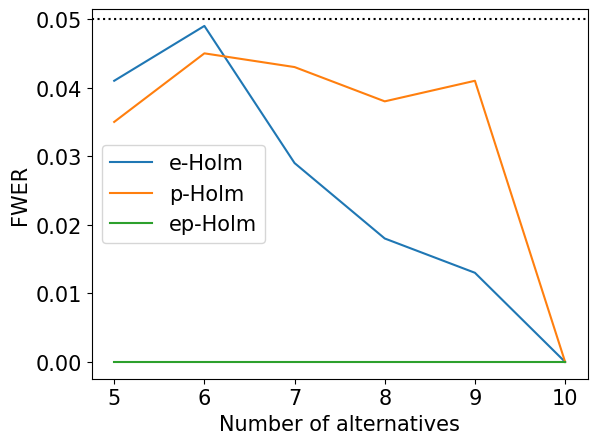

In [ ]:
plt.rcParams.update({'font.size': 15})
j = 1

plt.plot(n_1s, e_fwers[:,j], label = 'e-Holm')
plt.plot(n_1s, p_fwers[:,j], label = 'p-Holm')
plt.plot(n_1s, ep_fwers[:,j], label = 'ep-Holm')
plt.axhline(y=alpha, color = 'black', linestyle = 'dotted')
plt.legend()
#plt.title(f'FWER for Uniform Mixture with n = {n}, c = {cs[j]}')
plt.xlabel('Number of alternatives')
plt.ylabel('FWER')
plt.show()

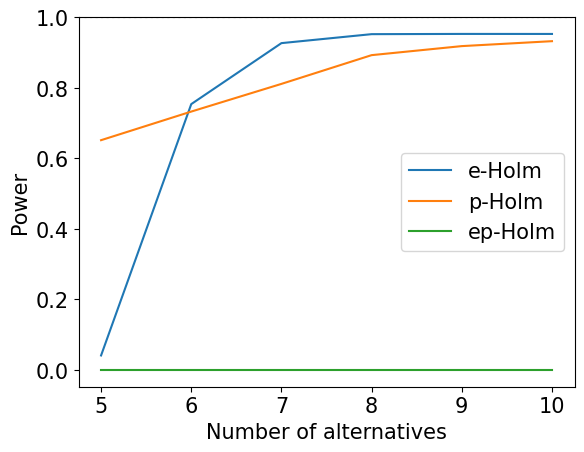

In [ ]:
#plt.plot(n_1s, [e_power(n, n_1, pi, cs[j], alpha) for n_1 in n_1s], color = colors[j], linestyle = '--')
#plt.plot(n_1s, [p_power(n_1, alpha, F1, n) for n_1 in n_1s], color = colors[j], linestyle = 'dashed')
plt.rcParams.update({'font.size': 15})
j = 1
F1 = lambda t: spike_mixture_p_cdf(t, c=cs[j], pi=pi)

plt.plot(n_1s, e_powers[:,j], label = 'e-Holm')
plt.plot(n_1s, p_powers[:,j], label = 'p-Holm')
plt.plot(n_1s, ep_powers[:,j], label = 'ep-Holm')

#plt.plot(n_1s, [e_power(n, n_1, pi, cs[j], alpha) for n_1 in n_1s], color = 'C0', linestyle = '--')
#plt.plot(n_1s, [p_power(n_1, alpha, F1, n) for n_1 in n_1s], color = 'C1', linestyle = '--')

plt.axhline(y=1, color = 'black', linestyle = 'dotted')
plt.legend()
#plt.title(f'Power for Uniform Mixture with n = {n}, c = {cs[j]}')
plt.xlabel('Number of alternatives')
plt.ylabel('Power')
plt.show()

In [ ]:
def e_power(n, n_1, pi, c, alpha):
  m_c = int(np.ceil(n+1-alpha/c))
  power = 0
  for m in range(m_c, n+1):
    power = power + m * math.comb(n_1, m) * pi ** (n_1 - m) * (1 - pi) ** m / n_1
  return power

In [ ]:
from math import comb
from typing import Callable

# this code created with chatgpt

def spike_mixture_p_cdf(t: float, c: float, pi: float) -> float:
    """
    CDF F1(t) of the NP p-value P = 1 - X under the alternative

        X ~ pi * Unif(0,1) + (1-pi) * Unif(1-c, 1)

    Parameters
    ----------
    t : float
        Threshold in [0, 1].
    c : float
        Spike width parameter in (0, 1].
    pi : float
        Mixture weight on the uniform component in [0, 1].

    Returns
    -------
    float
        F1(t) = P(P <= t) under the alternative.
    """
    if t <= 0:
        return 0.0
    if t >= 1:
        return 1.0
    if t <= c:
        return pi * t + (1.0 - pi) * (t / c)
    return (1.0 - pi) + pi * t


def holm_pr_at_least_r(
    n1: int,
    r: int,
    alpha: float,
    F1: Callable[[float], float],
    n_total: int | None = None,
) -> float:
    """
    Compute P(R >= r) for Holm applied to n1 alternative p-values only.

    This uses the exact multinomial/bin-count characterization, but computes
    it by dynamic programming.

    Parameters
    ----------
    n1 : int
        Number of alternative hypotheses being tracked.
    r : int
        Target number of Holm rejections.
    alpha : float
        Target FWER level.
    F1 : callable
        Alternative p-value CDF.
    n_total : int or None
        Total number of hypotheses in the family. If None, uses n_total = n1.
        If n_total > n1, this gives the "ignore nulls" benchmark where the
        alternatives face Holm thresholds alpha / (n_total - j + 1).

    Returns
    -------
    float
        Exact probability that Holm makes at least r rejections among the
        alternatives, ignoring null interference.
    """
    if not (0 <= r <= n1):
        raise ValueError("r must satisfy 0 <= r <= n1")
    if not (0 < alpha < 1):
        raise ValueError("alpha must be in (0, 1)")
    if n_total is None:
        n_total = n1
    if n_total < n1:
        raise ValueError("n_total must be >= n1")

    if r == 0:
        return 1.0

    # Holm thresholds t_j = alpha / (n_total - j + 1), j = 1,...,r
    t = [0.0]
    for j in range(1, r + 1):
        t.append(alpha / (n_total - j + 1))

    # Bin probabilities q_j = P(t_{j-1} < P <= t_j), j = 1,...,r
    q = []
    prev = 0.0
    for j in range(1, r + 1):
        cur = F1(t[j])
        prob = cur - prev
        if prob < -1e-12:
            raise ValueError("F1 must be nondecreasing")
        q.append(max(prob, 0.0))
        prev = cur

    # Tail probability after t_r
    tail = max(1.0 - F1(t[r]), 0.0)

    # DP over bins:
    # dp[s] = probability mass after processing current bins,
    #         having placed exactly s observations into the first processed bins,
    #         while satisfying the Holm prefix constraints so far.
    #
    # After processing bin j, we must have s >= j.
    dp = [0.0] * (n1 + 1)
    dp[0] = 1.0

    for j in range(1, r + 1):
        qj = q[j - 1]
        new_dp = [0.0] * (n1 + 1)

        for s_prev in range(n1 + 1):
            if dp[s_prev] == 0.0:
                continue

            remaining = n1 - s_prev
            # Put k observations into the current bin
            for k in range(remaining + 1):
                s_new = s_prev + k
                # Need S_j >= j
                if s_new < j:
                    continue
                new_dp[s_new] += dp[s_prev] * comb(remaining, k) * (qj ** k)

        dp = new_dp

    # Multiply by the tail contribution for the remaining observations
    prob = 0.0
    Ftr = F1(t[r])
    for s in range(r, n1 + 1):
        remaining = n1 - s
        prob += dp[s] * (tail ** remaining)

    # Numerical cleanup
    return min(max(prob, 0.0), 1.0)


def p_power(
    n1: int,
    alpha: float,
    F1: Callable[[float], float],
    n_total: int | None = None,
) -> float:
    """
    Compute E[R]/n1 using the exact identity E[R] = sum_{r=1}^{n1} P(R >= r),
    for the alternative-only / ignore-nulls Holm benchmark.

    Parameters
    ----------
    n1 : int
        Number of alternatives.
    alpha : float
        FWER level.
    F1 : callable
        Alternative p-value CDF.
    n_total : int or None
        Total family size used in Holm thresholds. If None, uses n_total = n1.

    Returns
    -------
    float
        E[R] / n1.
    """
    if n1 <= 0:
        return 0.0
    total = 0.0
    for r in range(1, n1 + 1):
        total += holm_pr_at_least_r(n1=n1, r=r, alpha=alpha, F1=F1, n_total=n_total)
    return total / n1

## Post-hoc plots

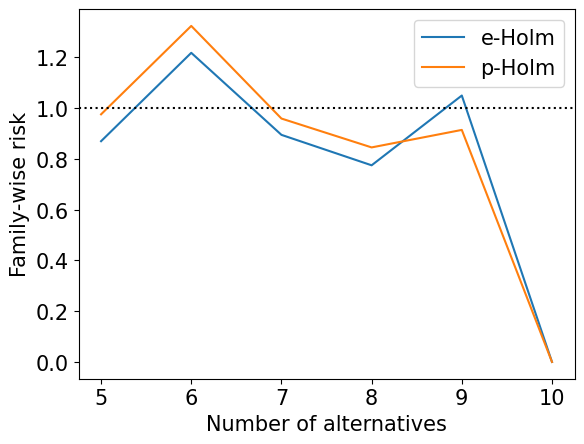

In [ ]:
plt.rcParams.update({'font.size': 15})
j = 1
plt.plot(n_1s, e_ph_fwers[:,j], label = 'e-Holm')
plt.plot(n_1s, p_ph_fwers[:,j], label = 'p-Holm')
plt.axhline(y=1, color = 'black', linestyle = 'dotted')
#plt.title(f'Post-hoc family-wise risk for Uniform Mixture with n = {n}, c = {cs[j]}')
plt.ylabel('Family-wise risk')
plt.xlabel('Number of alternatives')
plt.legend()
plt.show()

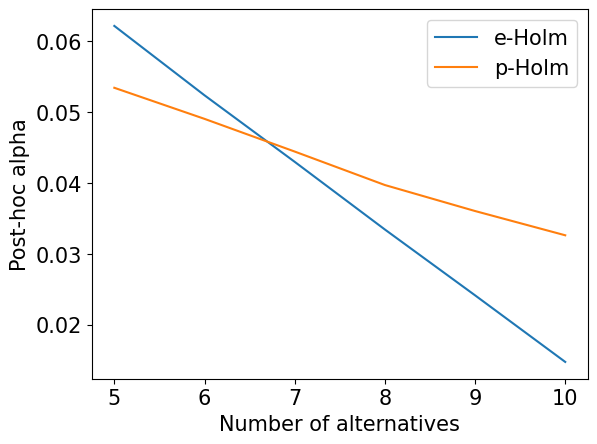

In [ ]:
plt.rcParams.update({'font.size': 15})
j = 1
plt.plot(n_1s, alpha_es[:,j], label = 'e-Holm')
plt.plot(n_1s, alpha_ps[:,j], label = 'p-Holm')
#plt.title(f'Post-hoc alphas for Uniform Mixture with n = {n}, c = {cs[j]}')
plt.ylabel('Post-hoc alpha')
plt.xlabel('Number of alternatives')
plt.legend()
plt.show()